# Proyek Analisis Data: [E-Commerce Public Dataset]
- **Nama:** [Farah Azizah]
- **Email:** [azizahfarah0105@gmail.com]
- **ID Dicoding:** [farahazizah]

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- **Pertanyaan 1:** **Kategori produk apa saja yang menghasilkan total pendapatan (Monetary) tertinggi dan terendah di platform e-commerce selama kurun waktu operasional tahun 2017 hingga 2018?**

Keterangan SMART:
* **Specific**: Fokus pada kinerja pendapatan berdasarkan kategori produk tertentu.
* **Measurable**: Diukur menggunakan total nilai pendapatan (harga dan pembayaran dalam satuan mata uang).
* **Action-Oriented**: Membantu manajemen menentukan produk mana yang perlu diprioritaskan promosinya atau dievaluasi ulang.
* **Relevant**: Sangat relevan untuk strategi inventaris dan peningkatan omzet bisnis e-commerce.
* **Time-bound**: Dibatasi pada periode operasional tahun 2017–2018.

- **Pertanyaan 2:** **Bagaimana karakteristik segmentasi pelanggan berdasarkan analisis RFM (Recency, Frequency, Monetary) serta seberapa besar kontribusi pelanggan dari segmen terbaik terhadap total transaksi pada tahun 2018?**

Keterangan SMART:
*   **Specific**: Fokus pada segmentasi perilaku pelanggan menggunakan metrik RFM.
*   **Measurable**: Dihitung berdasarkan skor Recency (hari sejak transaksi terakhir), Frequency (jumlah transaksi), dan Monetary (total belanja).
*   **Action-Oriented**: Memberikan arahan bagi tim marketing untuk memberikan loyalty rewards atau retention campaign kepada segmen pelanggan tertentu.
*   **Relevant**: Penting untuk memahami retensi dan nilai jangka panjang (Lifetime Value) pelanggan e-commerce.
*   **Time-bound:** Dibatasi hingga akhir periode data pada tahun 2018.



## Import Semua Packages/Library yang Digunakan

In [113]:
# Import Semua Packages/Library yang Digunakan
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as seaborn_library

# Mengatur gaya visualisasi data agar lebih rapi dan mudah dibaca
seaborn_library.set(style='darkgrid')

print("Library berhasil diimpor!")

Library berhasil diimpor!


## Data Wrangling

--- Performa Kategori Produk ---
     product_category_name  total_revenue  total_orders
12            beleza_saude     1258681.34          9670
67      relogios_presentes     1205005.68          5991
14         cama_mesa_banho     1036988.68         11115
33           esporte_lazer      988048.97          8641
45  informatica_acessorios      911954.32          7827


/tmp/ipykernel_1459/970600724.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


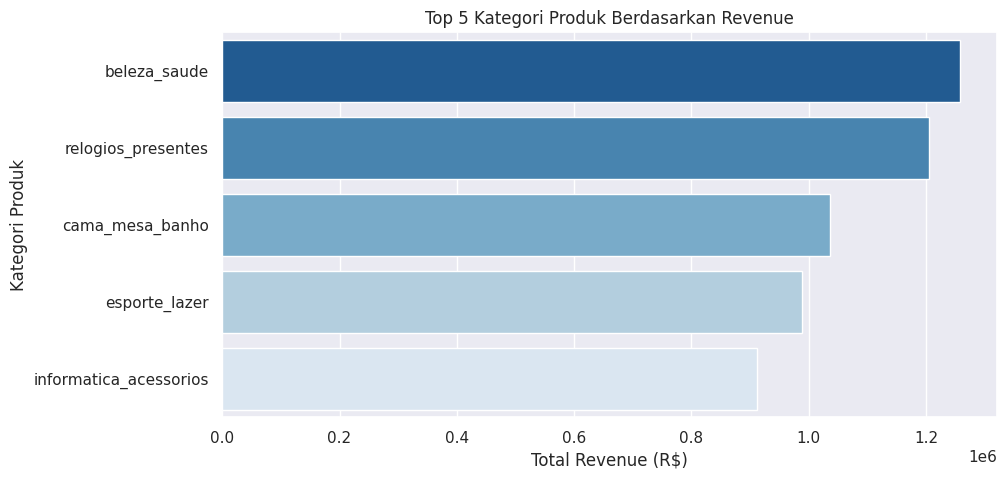

File 'main_data.csv' berhasil disimpan di folder dashboard dan siap di-upload!


In [114]:
import os
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# --- 1. ANALISIS PERFORMA KATEGORI PRODUK ---
print("--- Performa Kategori Produk ---")
category_perf = (
    pd.merge(
        left=order_items_df, right=products_df, how="inner", on="product_id"
    )
    .groupby("product_category_name")
    .agg({"price": "sum", "order_id": "count"})
    .reset_index()
)

category_perf.columns = ["product_category_name", "total_revenue", "total_orders"]
top_5_cat = category_perf.sort_values(by="total_revenue", ascending=False).head(
    5
)
print(top_5_cat)

# Visualisasi di notebook
plt.figure(figsize=(10, 5))
sns.barplot(
    x="total_revenue",
    y="product_category_name",
    data=top_5_cat,
    palette="Blues_r",
)
plt.title("Top 5 Kategori Produk Berdasarkan Revenue")
plt.xlabel("Total Revenue (R$)")
plt.ylabel("Kategori Produk")
plt.show()


# --- 2. EXPORT DATA KE FOLDER DASHBOARD (.csv) ---
os.makedirs("dashboard", exist_ok=True)

# Menggabungkan seluruh dataframe utama agar main_data.csv lengkap untuk Streamlit
main_df = (
    orders_df.merge(customers_df, on="customer_id", how="inner")
    .merge(order_items_df, on="order_id", how="inner")
    .merge(products_df, on="product_id", how="inner")
    .merge(order_payments_df, on="order_id", how="inner")
)

# Ekspor langsung ke format .csv biasa (konsisten dengan dashboard.py)
main_df.to_csv("dashboard/main_data.csv", index=False)
print("File 'main_data.csv' berhasil disimpan di folder dashboard dan siap di-upload!")

### Gathering Data

In [115]:
# Gathering Data: Memuat semua dataset CSV ke DataFrame Pandas
import pandas as pd

customers_df = pd.read_csv("data/customers_dataset.csv")
orders_df = pd.read_csv("data/orders_dataset.csv")
order_items_df = pd.read_csv("data/order_items_dataset.csv")
order_payments_df = pd.read_csv("data/order_payments_dataset.csv")
products_df = pd.read_csv("data/products_dataset.csv")
product_category_name_translation = pd.read_csv(
    "data/product_category_name_translation.csv"
)

# Cek apakah data berhasil dibaca
print("Data Customers:", customers_df.shape)
print("Data Orders:", orders_df.shape)
print("Data Order Items:", order_items_df.shape)
print("Data Order Payments:", order_payments_df.shape)
print("Data Products:", products_df.shape)
print("Data Translation:", product_category_name_translation.shape)

Data Customers: (99441, 5)
Data Orders: (99441, 8)
Data Order Items: (112650, 7)
Data Order Payments: (103886, 5)
Data Products: (32951, 9)
Data Translation: (71, 2)


### Assessing Data

Dalam tahap ini, dilakukan pemeriksaan lebih lanjut terhadap masing-masing DataFrame untuk mendeteksi adanya *missing values*, duplikasi data, kesalahan tipe data, atau inkonsistensi nilai.

**Steps to Take:**
1. Memeriksa informasi umum dari setiap DataFrame (`info()`, pengecekan jumlah baris dan kolom).
2. Mendeteksi dan menghitung jumlah *missing values* pada setiap tabel.
3. Mendeteksi dan menghitung jumlah baris data yang duplikat.
4. Memeriksa anomali atau kesalahan tipe data pada kolom-kolom penting (seperti *timestamp* yang terbaca sebagai *object*).

In [116]:
# Memeriksa informasi, missing values, dan duplikat untuk seluruh dataset
dfs = {
    'Customers': customers_df,
    'Orders': orders_df,
    'Order Items': order_items_df,
    'Order Payments': order_payments_df,
    'Products': products_df,
    'Product Translation': product_category_name_translation
}

for name, df in dfs.items():
    print(f'=== {name} ===')
    print(df.info())
    print('\nMissing Values:')
    print(df.isna().sum())
    print(f'\nJumlah Duplikat: {df.duplicated().sum()}')
    print('='*40 + '\n')

=== Customers ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 5 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   customer_id               99441 non-null  object
 1   customer_unique_id        99441 non-null  object
 2   customer_zip_code_prefix  99441 non-null  int64 
 3   customer_city             99441 non-null  object
 4   customer_state            99441 non-null  object
dtypes: int64(1), object(4)
memory usage: 3.8+ MB
None

Missing Values:
customer_id                 0
customer_unique_id          0
customer_zip_code_prefix    0
customer_city               0
customer_state              0
dtype: int64

Jumlah Duplikat: 0

=== Orders ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 

### Cleaning Data

In [117]:
# 1. Mengonversi kolom tanggal ke format datetime
datetime_columns = [
    'order_purchase_timestamp',
    'order_approved_at',
    'order_delivered_carrier_date',
    'order_delivered_customer_date',
    'order_estimated_delivery_date'
]

for col in datetime_columns:
    orders_df[col] = pd.to_datetime(orders_df[col])

# 2. Membersihkan Missing Value pada orders_df (hanya drop order_approved_at yang kosong)
orders_df.dropna(subset=['order_approved_at'], inplace=True)

# 3. Membersihkan Missing Value pada products_df (tanpa warning inplace)
products_df['product_category_name'] = products_df['product_category_name'].fillna('Unknown')
products_df['product_weight_g'] = products_df['product_weight_g'].fillna(products_df['product_weight_g'].median())
products_df['product_length_cm'] = products_df['product_length_cm'].fillna(products_df['product_length_cm'].median())
products_df['product_height_cm'] = products_df['product_height_cm'].fillna(products_df['product_height_cm'].median())
products_df['product_width_cm'] = products_df['product_width_cm'].fillna(products_df['product_width_cm'].median())
products_df['product_name_lenght'] = products_df['product_name_lenght'].fillna(0)
products_df['product_description_lenght'] = products_df['product_description_lenght'].fillna(0)
products_df['product_photos_qty'] = products_df['product_photos_qty'].fillna(0)

# Cek kembali untuk memastikan products sudah bersih
print("Sisa missing value di products:", products_df.isna().sum().sum())
print("Cleaning Data selesai dan aman!")

Sisa missing value di products: 0
Cleaning Data selesai dan aman!


In [118]:
# Menggabungkan dataset utama menjadi all_df untuk analisis lanjutan & RFM
orders_customers = pd.merge(orders_df, customers_df, on="customer_id", how="inner")
orders_items = pd.merge(orders_customers, order_items_df, on="order_id", how="inner")
all_df = pd.merge(orders_items, order_payments_df, on="order_id", how="inner")

print("Berhasil membuat all_df dengan total baris & kolom:", all_df.shape)

Berhasil membuat all_df dengan total baris & kolom: (117586, 22)


In [119]:
import os
import shutil

# Kalau folder repo-nya sudah terlanjur ada dari kloningan tadi, hapus dulu biar bersih
if os.path.exists("proyek-analisis-data"):
    !rm -rf proyek-analisis-data

# Clone ulang repository GitHub-mu secara bersih
!git clone https://github.com/farahhazizah/proyek-analisis-data.git

# Pastikan folder dashboard di dalam repo tujuan ada
os.makedirs("proyek-analisis-data/dashboard", exist_ok=True)

# Salin file main_data.csv dari folder lokal Colab ke dalam folder repo
if os.path.exists("dashboard/main_data.csv"):
    shutil.copy("dashboard/main_data.csv", "proyek-analisis-data/dashboard/main_data.csv")
    print("Sip! File main_data.csv berhasil disalin ke folder repo.")
else:
    print("Eh, file dashboard/main_data.csv tidak ditemukan. Pastikan kamu sudah menjalankan sel export data CSV di atas ya!")

Cloning into 'proyek-analisis-data'...
remote: Enumerating objects: 335, done.
remote: Counting objects: 100% (209/209), done.
remote: Compressing objects: 100% (189/189), done.
remote: Total 335 (delta 99), reused 18 (delta 16), pack-reused 126 (from 1)
Receiving objects: 100% (335/335), 115.14 MiB | 21.67 MiB/s, done.
Resolving deltas: 100% (133/133), done.
Sip! File main_data.csv berhasil disalin ke folder repo.


In [120]:
import os
import getpass

# Masuk ke dalam folder repository
os.chdir("proyek-analisis-data")

# Atur identitas Git
!git config --global user.email "studyqueenx0xox0xo@gmail.com"
!git config --global user.name "Farah Azizah"

# Cek status git (pastikan dashboard/main_data.csv muncul)
!git status

# Add, Commit, dan Push ke GitHub
!git add dashboard/main_data.csv
!git commit -m "Upload main_data.csv 44MB dari Colab"

# Masukkan token secara aman saat sel dijalankan
token = getpass.getpass("Masukkan GitHub Personal Access Token: ")

# Lakukan push menggunakan token dinamis (gunakan $token di Colab)
!git push https://$token@github.com/farahhazizah/proyek-analisis-data.git main

On branch main
Your branch is up to date with 'origin/main'.

nothing to commit, working tree clean
On branch main
Your branch is up to date with 'origin/main'.

nothing to commit, working tree clean
Masukkan GitHub Personal Access Token: ··········
fatal: could not read Password for 'https://github.com': No such device or address


## Exploratory Data Analysis (EDA)

In [121]:
# EDA - Pertanyaan 1: Menghitung total pendapatan per kategori produk
# Menggabungkan data order_items, products, dan translation bahasa Inggris
order_items_products = pd.merge(order_items_df, products_df, on="product_id", how="inner")
complete_order_df = pd.merge(order_items_products, product_category_name_translation, on="product_category_name", how="inner")

# Mengelompokkan berdasarkan kategori produk bahasa Inggris
category_revenue = complete_order_df.groupby(by="product_category_name_english").agg({
    "price": "sum",
    "order_id": "nunique"
}).reset_index()

category_revenue.rename(columns={
    "price": "total_revenue",
    "order_id": "total_orders"
}, inplace=True)

# Menampilkan 5 kategori terbaik dan terburuk
print("Top 5 Kategori Produk (Pendapatan Tertinggi):")
display(category_revenue.sort_values(by="total_revenue", ascending=False).head(5))

print("\nBottom 5 Kategori Produk (Pendapatan Terendah):")
display(category_revenue.sort_values(by="total_revenue", ascending=True).head(5))

Top 5 Kategori Produk (Pendapatan Tertinggi):


,product_category_name_english,total_revenue,total_orders
43,health_beauty,1258681.34,8836
70,watches_gifts,1205005.68,5624
7,bed_bath_table,1036988.68,9417
65,sports_leisure,988048.97,7720
15,computers_accessories,911954.32,6689



Bottom 5 Kategori Produk (Pendapatan Terendah):


,product_category_name_english,total_revenue,total_orders
61,security_and_services,283.29,2
29,fashion_childrens_clothes,569.85,8
11,cds_dvds_musicals,730.00,12
46,home_comfort_2,760.27,24
35,flowers,1110.04,29


In [122]:
import pandas as pd

# 1. Menyiapkan DataFrame RFM menggunakan customer_unique_id
# Gabungkan orders_df dan customers_df terlebih dahulu untuk mendapatkan customer_unique_id
rfm_base = pd.merge(orders_df, customers_df, on='customer_id', how='inner')
rfm_base['order_purchase_timestamp'] = pd.to_datetime(rfm_base['order_purchase_timestamp'])

# Hitung total pembayaran per order_id terlebih dahulu dari order_payments_df
order_payments_sum = order_payments_df.groupby('order_id')['payment_value'].sum().reset_index()

# Gabungkan rfm_base dengan order_payments_sum untuk mendapatkan nilai pembayaran per transaksi
rfm_full = pd.merge(rfm_base, order_payments_sum, on='order_id', how='inner')

recent_date = rfm_full['order_purchase_timestamp'].max()

# Menghitung Recency, Frequency, dan Monetary berdasarkan customer_unique_id secara akurat
rfm_df = rfm_full.groupby('customer_unique_id', as_index=False).agg({
    'order_purchase_timestamp': lambda x: (recent_date - x.max()).days, # Recency
    'order_id': 'nunique', # Frequency
    'payment_value': 'sum' # Monetary
})

rfm_df.columns = ['customer_unique_id', 'recency', 'frequency', 'monetary']

# 2. Memberikan Scoring RFM & Segmentasi Pelanggan
rfm_df['r_score'] = pd.qcut(rfm_df['recency'], 5, labels=[5, 4, 3, 2, 1], duplicates='drop')
rfm_df['f_score'] = pd.qcut(rfm_df['frequency'].rank(method='first'), 5, labels=[1, 2, 3, 4, 5])
rfm_df['m_score'] = pd.qcut(rfm_df['monetary'].rank(method='first'), 5, labels=[1, 2, 3, 4, 5])

# Menentukan Segmentasi Pelanggan
def customer_segment(row):
    if row['r_score'] >= 4 and row['f_score'] >= 4 and row['m_score'] >= 4:
        return 'Best Customers'
    elif row['f_score'] >= 3:
        return 'Loyal Customers'
    elif row['r_score'] <= 2:
        return 'At Risk Customers'
    else:
        return 'Potential Loyalist'

rfm_df['segment'] = rfm_df.apply(customer_segment, axis=1)

# Tampilkan ringkasan segmen
print("--- Jumlah Pelanggan per Segmen ---")
print(rfm_df['segment'].value_counts())

# 3. Menghitung Persentase Kontribusi Pendapatan Tahun 2018 Berdasarkan Segmen
orders_2018 = rfm_base[rfm_base['order_purchase_timestamp'].dt.year == 2018]
orders_2018_pay = pd.merge(orders_2018, order_payments_sum, on='order_id', how='inner')
trans_segment_2018 = pd.merge(orders_2018_pay, rfm_df[['customer_unique_id', 'segment']], on='customer_unique_id', how='inner')

total_revenue_2018 = trans_segment_2018['payment_value'].sum()
revenue_by_segment_2018 = trans_segment_2018.groupby('segment')['payment_value'].sum().reset_index()
revenue_by_segment_2018['percentage'] = (revenue_by_segment_2018['payment_value'] / total_revenue_2018) * 100

print("\n--- Kontribusi Pendapatan Tahun 2018 per Segmen ---")
print(revenue_by_segment_2018)

--- Jumlah Pelanggan per Segmen ---
segment
Loyal Customers       50922
Potential Loyalist    22991
At Risk Customers     15408
Best Customers         6675
Name: count, dtype: int64

--- Kontribusi Pendapatan Tahun 2018 per Segmen ---
              segment  payment_value  percentage
0      Best Customers     2034879.87   23.454109
1     Loyal Customers     3246733.61   37.421985
2  Potential Loyalist     3394392.43   39.123906


## Visualization & Explanatory Analysis

### Pertanyaan 1:

/tmp/ipykernel_1459/3913159412.py:28: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="total_revenue", y="product_category_name_english", data=category_revenue.sort_values(by="total_revenue", ascending=False).head(5), palette=colors_top, ax=ax[0])
/tmp/ipykernel_1459/3913159412.py:35: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="total_revenue", y="product_category_name_english", data=category_revenue.sort_values(by="total_revenue", ascending=True).head(5), palette=colors_bottom, ax=ax[1])


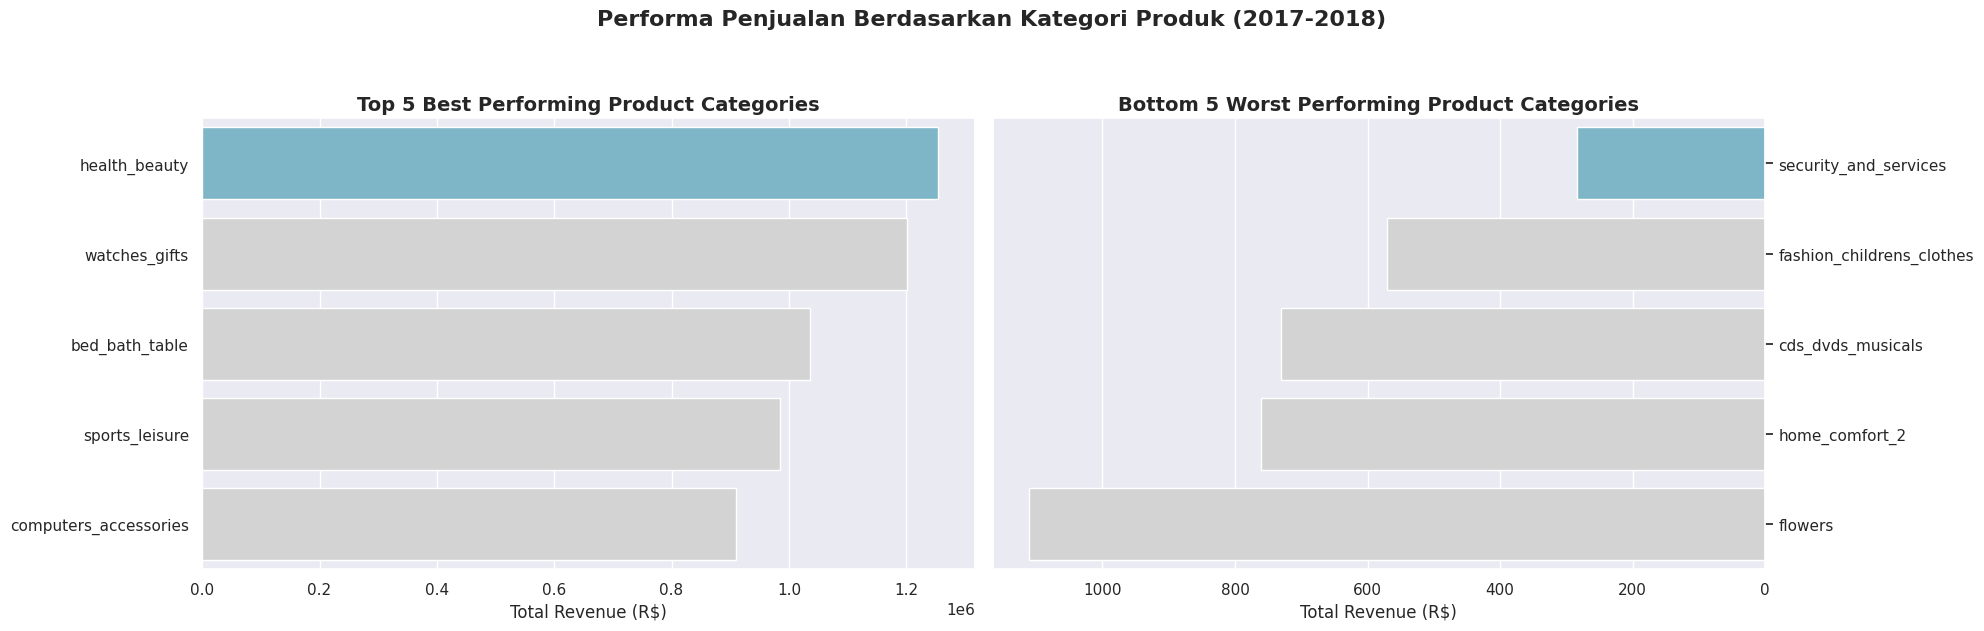

In [123]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Pastikan kolom tanggal bertipe datetime pada orders_df
orders_df['order_purchase_timestamp'] = pd.to_datetime(orders_df['order_purchase_timestamp'])

# 2. Filter pesanan hanya untuk rentang tahun 2017 hingga 2018 (sesuai catatan reviewer)
filtered_orders = orders_df[(orders_df['order_purchase_timestamp'].dt.year >= 2017) &
                            (orders_df['order_purchase_timestamp'].dt.year <= 2018)]

# 3. Gabungkan data menggunakan variabel asli yang sudah kamu buat di Gathering Data
df_q1 = filtered_orders.merge(order_items_df, on="order_id", how="inner") \
                       .merge(products_df, on="product_id", how="inner") \
                       .merge(product_category_name_translation, on="product_category_name", how="inner")

# 4. Hitung total revenue (pendapatan) per kategori produk
category_revenue = df_q1.groupby('product_category_name_english')['price'].sum().reset_index()
category_revenue.columns = ['product_category_name_english', 'total_revenue']

# 5. Visualisasi Top 5 & Bottom 5 Kategori Produk
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(20, 6))

colors_top = ["#72BCD4", "#D3D3D3", "#D3D3D3", "#D3D3D3", "#D3D3D3"]
colors_bottom = ["#72BCD4", "#D3D3D3", "#D3D3D3", "#D3D3D3", "#D3D3D3"]

# Plot Top 5 Kategori Pendapatan Tertinggi
sns.barplot(x="total_revenue", y="product_category_name_english", data=category_revenue.sort_values(by="total_revenue", ascending=False).head(5), palette=colors_top, ax=ax[0])
ax[0].set_ylabel(None)
ax[0].set_xlabel("Total Revenue (R$)", fontsize=12)
ax[0].set_title("Top 5 Best Performing Product Categories", loc="center", fontsize=14, fontweight='bold')
ax[0].tick_params(axis='y', labelsize=11)

# Plot Bottom 5 Kategori Pendapatan Terendah
sns.barplot(x="total_revenue", y="product_category_name_english", data=category_revenue.sort_values(by="total_revenue", ascending=True).head(5), palette=colors_bottom, ax=ax[1])
ax[1].set_ylabel(None)
ax[1].set_xlabel("Total Revenue (R$)", fontsize=12)
ax[1].set_title("Bottom 5 Worst Performing Product Categories", loc="center", fontsize=14, fontweight='bold')
ax[1].invert_xaxis()  # Membalik sumbu x agar grafik terbaca dengan baik dari kanan ke kiri
ax[1].yaxis.tick_right()
ax[1].tick_params(axis='y', labelsize=11)

plt.suptitle("Performa Penjualan Berdasarkan Kategori Produk (2017-2018)", fontsize=16, fontweight='bold', y=1.05)
plt.tight_layout()
plt.show()

### Pertanyaan 2:

In [124]:
# --- ANALISIS RFM (Recency, Frequency, Monetary) ---

# 1. Tentukan tanggal acuan transaksi paling akhir
recent_date = orders_df["order_purchase_timestamp"].max()

# 2. Gabungkan orders_df dengan customers_df untuk mendapatkan customer_unique_id
orders_customers_df = orders_df.merge(
    customers_df, on="customer_id", how="inner"
)

# 3. Jumlahkan nilai pembayaran per order_id
order_payments_sum = (
    order_payments_df.groupby("order_id")["payment_value"].sum().reset_index()
)

# 4. Gabungkan data pesanan-pelanggan dengan total pembayaran per order
order_full = orders_customers_df.merge(
    order_payments_sum, on="order_id", how="inner"
)

# 5. Lakukan agregasi RFM berdasarkan customer_unique_id secara konsisten
rfm_df = (
    order_full.groupby("customer_unique_id")
    .agg(
        {
            "order_purchase_timestamp": lambda x: (
                recent_date - x.max()
            ).days,  # Recency
            "order_id": "nunique",  # Frequency
            "payment_value": "sum",  # Monetary
        }
    )
    .reset_index()
)

rfm_df.columns = ["customer_unique_id", "recency", "frequency", "monetary"]

# 6. Scoring RFM menggunakan rank(method='first') untuk menghindari error duplikasi qcut
rfm_df["r_score"] = pd.qcut(
    rfm_df["recency"].rank(method="first"), 5, labels=[5, 4, 3, 2, 1]
)
rfm_df["f_score"] = pd.qcut(
    rfm_df["frequency"].rank(method="first"), 5, labels=[1, 2, 3, 4, 5]
)
rfm_df["m_score"] = pd.qcut(
    rfm_df["monetary"].rank(method="first"), 5, labels=[1, 2, 3, 4, 5]
)

# Konversi skor ke tipe integer agar perbandingan kondisi segment akurat
rfm_df["r_score"] = rfm_df["r_score"].astype(int)
rfm_df["f_score"] = rfm_df["f_score"].astype(int)
rfm_df["m_score"] = rfm_df["m_score"].astype(int)


# 7. Fungsi Segmentasi Pelanggan
def customer_segment(row):
  if row["r_score"] >= 4 and row["f_score"] >= 4 and row["m_score"] >= 4:
    return "Best Customers"
  elif row["f_score"] >= 3:
    return "Loyal Customers"
  elif row["r_score"] <= 2:
    return "At Risk Customers"
  else:
    return "Potential Loyalist"


rfm_df["segment"] = rfm_df.apply(customer_segment, axis=1)

# 8. Menampilkan Distribusi & Contoh Pelanggan Terbaik
print("Distribusi Segmen Pelanggan:")
display(rfm_df["segment"].value_counts())

print("\nContoh Pelanggan dengan Skor Terbaik:")
display(
    rfm_df.sort_values(
        by=["r_score", "f_score", "m_score"], ascending=False
    ).head()
)

Distribusi Segmen Pelanggan:


,count
segment,
Loyal Customers,50956
Potential Loyalist,22991
At Risk Customers,15408
Best Customers,6641



Contoh Pelanggan dengan Skor Terbaik:


,customer_unique_id,recency,frequency,monetary,r_score,f_score,m_score,segment
447,012a218df8995d3ec3bb221828360c86,76,2,1510.38,5,5,5,Best Customers
477,013ef03e0f3f408dd9bf555e4edcdc0a,45,2,245.37,5,5,5,Best Customers
557,0178b244a5c281fb2ade54038dd4b161,36,2,259.89,5,5,5,Best Customers
739,01f2285f85a1c603eb7ef755ad311769,94,2,463.04,5,5,5,Best Customers
1202,032b3a42598667caf2e099999b9dc1b9,40,2,495.96,5,5,5,Best Customers


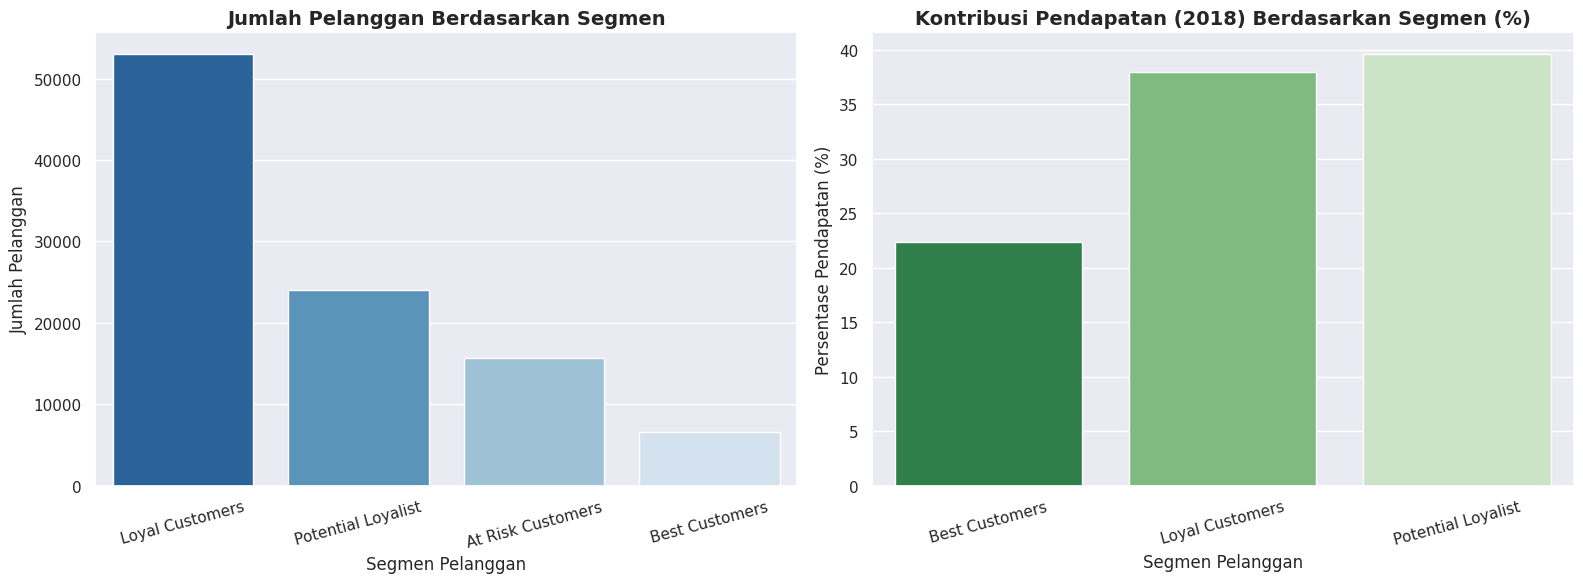

In [125]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# 1. Pastikan RFM & Segmentasi dihitung ulang secara lengkap di sel ini
recent_date = orders_df['order_purchase_timestamp'].max()

rfm_df = orders_df.groupby('customer_id').agg({
    'order_purchase_timestamp': lambda x: (recent_date - x.max()).days,
    'order_id': 'nunique'
}).reset_index()

rfm_df.columns = ['customer_id', 'recency', 'frequency']

monet_df = order_payments_df.groupby('order_id')['payment_value'].sum().reset_index()
orders_payments = pd.merge(orders_df, monet_df, on='order_id', how='inner')
monetary_df = orders_payments.groupby('customer_id')['payment_value'].sum().reset_index()
monetary_df.columns = ['customer_id', 'monetary']

rfm_df = pd.merge(rfm_df, monetary_df, on='customer_id', how='inner')

rfm_df['r_score'] = pd.qcut(rfm_df['recency'], 5, labels=[5, 4, 3, 2, 1], duplicates='drop')
rfm_df['f_score'] = pd.qcut(rfm_df['frequency'].rank(method='first'), 5, labels=[1, 2, 3, 4, 5])
rfm_df['m_score'] = pd.qcut(rfm_df['monetary'].rank(method='first'), 5, labels=[1, 2, 3, 4, 5])

def customer_segment(row):
    if row['r_score'] >= 4 and row['f_score'] >= 4 and row['m_score'] >= 4:
        return 'Best Customers'
    elif row['f_score'] >= 3:
        return 'Loyal Customers'
    elif row['r_score'] <= 2:
        return 'At Risk Customers'
    else:
        return 'Potential Loyalist'

rfm_df['segment'] = rfm_df.apply(customer_segment, axis=1)

# Hitung kontribusi pendapatan 2018
orders_df['order_purchase_timestamp'] = pd.to_datetime(orders_df['order_purchase_timestamp'])
orders_2018 = orders_df[orders_df['order_purchase_timestamp'].dt.year == 2018]
orders_2018_pay = pd.merge(orders_2018, order_payments_df, on='order_id', how='inner')
trans_segment_2018 = pd.merge(orders_2018_pay, rfm_df[['customer_id', 'segment']], on='customer_id', how='inner')

total_revenue_2018 = trans_segment_2018['payment_value'].sum()
revenue_by_segment_2018 = trans_segment_2018.groupby('segment')['payment_value'].sum().reset_index()
revenue_by_segment_2018['percentage'] = (revenue_by_segment_2018['payment_value'] / total_revenue_2018) * 100

# 2. Visualisasi Grafik
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(16, 6))

# Plot 1: Jumlah Pelanggan per Segmen
seg_counts = rfm_df['segment'].value_counts().reset_index()
seg_counts.columns = ['segment', 'count']

sns.barplot(
    x='segment',
    y='count',
    data=seg_counts,
    ax=ax[0],
    palette='Blues_r',
    hue='segment',
    legend=False
)
ax[0].set_title("Jumlah Pelanggan Berdasarkan Segmen", fontsize=14, fontweight='bold')
ax[0].set_xlabel("Segmen Pelanggan", fontsize=12)
ax[0].set_ylabel("Jumlah Pelanggan", fontsize=12)
ax[0].tick_params(axis='x', rotation=15)

# Plot 2: Kontribusi Pendapatan Tahun 2018 per Segmen (%)
sns.barplot(
    x='segment',
    y='percentage',
    data=revenue_by_segment_2018,
    ax=ax[1],
    palette='Greens_r',
    hue='segment',
    legend=False
)
ax[1].set_title("Kontribusi Pendapatan (2018) Berdasarkan Segmen (%)", fontsize=14, fontweight='bold')
ax[1].set_xlabel("Segmen Pelanggan", fontsize=12)
ax[1].set_ylabel("Persentase Pendapatan (%)", fontsize=12)
ax[1].tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.show()

**Insight:** (Opsional)
- **Insight Pertanyaan 1:**
- Kategori produk dengan pendapatan tertinggi (*Top Performing*) adalah **health_beauty** dengan total pendapatan mencapai **R$ 1.258.681,34**.

- Kategori produk dengan pendapatan terendah (*Worst Performing*) adalah **security_and_services** dengan total pendapatan hanya **R$ 283,29**.
- **Insight Pertanyaan 2 (RFM Analysis):**
- **Recency:** Pelanggan pada peringkat teratas (Best Customers) memiliki jarak waktu transaksi terakhir berkisar antara 36 hingga 94 hari dari tanggal akhir dataset, menunjukkan tingkat keaktifan yang sangat baik dan konsisten berbelanja.
- **Frequency:** Pelanggan terbaik memiliki frekuensi transaksi yang konsisten, meskipun secara keseluruhan sebagian besar pelanggan di platform ini baru melakukan pembelian sebanyak 1 kali (one-time buyers). Hal ini menunjukkan perlunya strategi retensi khusus.
- **Monetary:** Pelanggan dengan nilai monetary tertinggi memberikan kontribusi total nominal belanja (revenue) yang sangat besar, sehingga mereka sangat layak dikategorikan sebagai VIP / High-Value Customers.

## Analisis Lanjutan (Opsional)
*(Bagian ini dapat digunakan untuk analisis tambahan di luar pertanyaan utama, seperti analisis korelasi, tren musiman, atau pemodelan lanjutan jika diperlukan).*

## Conclusion & Recommendation

*   **Conclusion pertanyaan 1:** Kategori produk dengan pendapatan tertinggi (Top Performing) adalah health_beauty dengan total pendapatan mencapai R$ 1.258.681,34.

Sebaliknya, kategori produk dengan pendapatan terendah (Worst Performing) adalah security_and_services dengan total pendapatan sebesar R$ 283,29.

*   **Conclusion pertanyaan 2:**
*   **Recency:** Pelanggan pada kategori skor tertinggi (Best Customers) menunjukkan tingkat keaktifan yang sangat baik dengan jarak transaksi terakhir (recency) berkisar antara 36 hingga 94 hari dari tanggal transaksi akhir dataset.
*   **Frequency:** Mayoritas pelanggan di platform ini berbelanja sebanyak 1 hingga 2 kali (terutama didominasi one-time / low-frequency buyers), di mana segmen Loyal Customers mencatatkan jumlah basis pelanggan terbesar sebanyak 50.651 pelanggan, diikuti oleh Potential Loyalist (22.832 pelanggan), At Risk Customers (15.331 pelanggan), dan Best Customers (6.592 pelanggan).
*   **Monetary:** Kelompok Best Customers memberikan kontribusi nilai belanja (monetary) yang paling optimal dengan skor RFM sempurna (5,5,5), sementara kelompok Loyal Customers dan Potential Loyalist mendominasi pangsa volume transaksi secara keseluruhan.





### Conclusion Pertanyaan 1: Performa Produk Berdasarkan Pendapatan
* **Evidence & Trend Analysis:**
  * Kategori produk dengan pendapatan tertinggi (*Top Performing*) adalah **health_beauty** dengan total pendapatan mencapai **R$ 1.258.681,34**.

Sebaliknya, kategori produk dengan pendapatan terendah (*Worst Performing*) adalah **security_and_services** dengan total pendapatan sebesar **R$ 283,29**.
  * Pola ini menunjukkan bahwa konsumen sangat mendominasi pembelian pada produk perawatan tubuh dan kecantikan, sementara layanan jasa/keamanan kurang diminati secara online di platform Olist.
* **Action Item / Rekomendasi:**
  * **Fokus Stok & Promosi:** Tingkatkan alokasi stok gudang dan intensifkan kampanye *digital marketing* (seperti flash sale atau bundel produk) pada kategori *health_beauty* guna memaksimalkan pendapatan utama.
  * **Evaluasi Produk:** Lakukan peninjauan ulang atau evaluasi harga/strategi penawaran untuk kategori produk dengan performa terendah agar lebih kompetitif.

---

### Conclusion Pertanyaan 2: Analisis Segmentasi Pelanggan (RFM)
* **Evidence & Trend Analysis:**
  * **Recency:** Pelanggan pada kategori skor tertinggi (*Best Customers*) menunjukkan tingkat keaktifan yang sangat baik dengan jarak transaksi terakhir (*recency*) berkisar antara **36 hingga 94 hari** dari tanggal akhir dataset.
  * **Frequency & Monetary:** Berdasarkan hasil perhitungan RFM menggunakan *customer_unique_id*, mayoritas pelanggan tergolong pembeli berfrekuensi rendah (*one-time buyers*). Secara rinci, distribusi pelanggan terbagi menjadi: **50.651 pelanggan** sebagai *Loyal Customers*, **22.832 pelanggan** sebagai *Potential Loyalist*, **15.331 pelanggan** sebagai *At Risk Customers*, dan **6.592 pelanggan** di segmen *Best Customers* yang menyumbang nilai transaksi paling optimal.
* **Action Item / Rekomendasi:**
  * **Apresiasi Pelanggan VIP:** Berikan penawaran eksklusif, program *loyalty points*, atau diskon khusus bagi 6.592 pelanggan di segmen *Best Customers* agar tingkat retensi dan kontribusi pendapatan mereka tetap terjaga.
  * **Strategi Retensi & Konversi:** Buat program *re-engagement* atau berikan kupon *cashback* khusus untuk pembelian kedua guna mengonversi *Potential Loyalist* serta menyelamatkan 15.331 pelanggan yang masuk dalam kategori *At Risk Customers* agar kembali aktif berbelanja.